## Marketing Analytics Chapter 3

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Read in the chapter data from GitHub Repo

In [2]:
bank1 = pd.read_csv("https://raw.githubusercontent.com/librowndev/Data-Science-for-Marketing-Analytics-Second-Edition/refs/heads/master/Chapter03/Datasets/Bank_Personal_Loan_Modelling-1.csv")

In [3]:
bank1.head()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [4]:
bank2 = pd.read_csv('https://raw.githubusercontent.com/PacktPublishing/Data-Science-for-Marketing-Analytics-Second-Edition/refs/heads/master/Chapter03/Datasets/Bank_Personal_Loan_Modelling-2.csv')

In [5]:
bank2.head()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,Primary,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,Primary,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,Primary,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,Secondary,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,Secondary,0,0,0,0,0,1


In [6]:
clothing_customers = pd.read_csv('https://raw.githubusercontent.com/PacktPublishing/Data-Science-for-Marketing-Analytics-Second-Edition/refs/heads/master/Chapter03/Datasets/Clothing_Customers.csv')

In [7]:
clothing_customers.head()

,income,age,days_since_purchase,annual_spend
0,37453,48,504,4441
1,50775,50,566,4239
2,71047,41,326,5834
3,52239,52,259,5456
4,112343,27,279,1749


In [8]:
mail_customers = pd.read_csv('https://raw.githubusercontent.com/PacktPublishing/Data-Science-for-Marketing-Analytics-Second-Edition/refs/heads/master/Chapter03/Datasets/Mall_Customers.csv')

In [9]:
mail_customers.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [10]:
age_education = pd.read_csv('https://raw.githubusercontent.com/PacktPublishing/Data-Science-for-Marketing-Analytics-Second-Edition/refs/heads/master/Chapter03/Datasets/age_education.csv')

In [11]:
age_education.head()

,age,education
0,27.007219,Tertiary
1,47.615409,Secondary
2,51.382815,Secondary
3,54.906622,Secondary
4,27.719939,Primary


In [12]:
customer_offers = pd.read_csv('https://raw.githubusercontent.com/PacktPublishing/Data-Science-for-Marketing-Analytics-Second-Edition/refs/heads/master/Chapter04/Datasets/customer_offers.csv')

In [13]:
customer_offers.head()

,1,2,3,4,5,6,7,8,9,10,...,23,24,25,26,27,28,29,30,31,32
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,0,0
1,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,1,0,1,0,0,0,0,0,0
3,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,0,0,0,0,0,0,1,0,0,1,...,0,0,0,0,0,0,0,0,1,0


#### Exercise 3.01

In [14]:
# 3 (1 -> read datam 2 -> head())
mail_customers.info()


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [15]:
# 4 rename columns

mail_customers.rename({'Annual Income (k$)': 'Income', "Spending Score (1-100)": 'Spending_score'}, axis=1, inplace=True)

mail_customers.columns

Index(['CustomerID', 'Gender', 'Age', 'Income', 'Spending_score'], dtype='str')

In [16]:
mail_customers.describe()

,CustomerID,Age,Income,Spending_score
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## Mall Customers Dataset

**Source:** [Packt – Data Science for Marketing Analytics, 2nd Ed. (Chapter 3)](https://raw.githubusercontent.com/PacktPublishing/Data-Science-for-Marketing-Analytics-Second-Edition/refs/heads/master/Chapter03/Datasets/Mall_Customers.csv)

**Overview:** A small, clean customer-segmentation dataset with **200 rows × 5 columns**, one row per mall customer. A standard teaching set for clustering (e.g., K-means).

| Column | Type | Notes |
|---|---|---|
| `CustomerID` | int | Unique key, 1–200 |
| `Gender` | categorical | Male / Female (~112 Female, ~88 Male) |
| `Age` | int | Range 18–70, mean ≈ 39 |
| `Annual Income (k$)` | int | Range 15–137, mean ≈ 60.6 |
| `Spending Score (1-100)` | int | Mall-assigned score based on behavior and spending; range 1–99, mean ≈ 50 |

### Key Observations
- **No missing values** or malformed rows.
- **Income** is right-skewed, with a few high earners at 120–137k.
- **Spending score** isn't driven by income alone. Income vs. spending score shows roughly **5 groups**:
  - low income / low spending
  - low income / high spending
  - mid income / mid spending (largest group)
  - high income / low spending
  - high income / high spending
- **Age:** younger customers (under ~40) dominate the high-spending groups; older customers cluster at low-to-mid scores.
- **Gender** differences are modest.

### Practical Notes
- Rename `Annual Income (k$)` and `Spending Score (1-100)` to clean names (e.g., `annual_income`, `spending_score`) to avoid issues with spaces and symbols.
- For clustering, **scale** Age, Income, and Spending Score first; use `CustomerID` only as an identifier.


### Exercise 3.02 Traditional Segmentation of Mall Customers

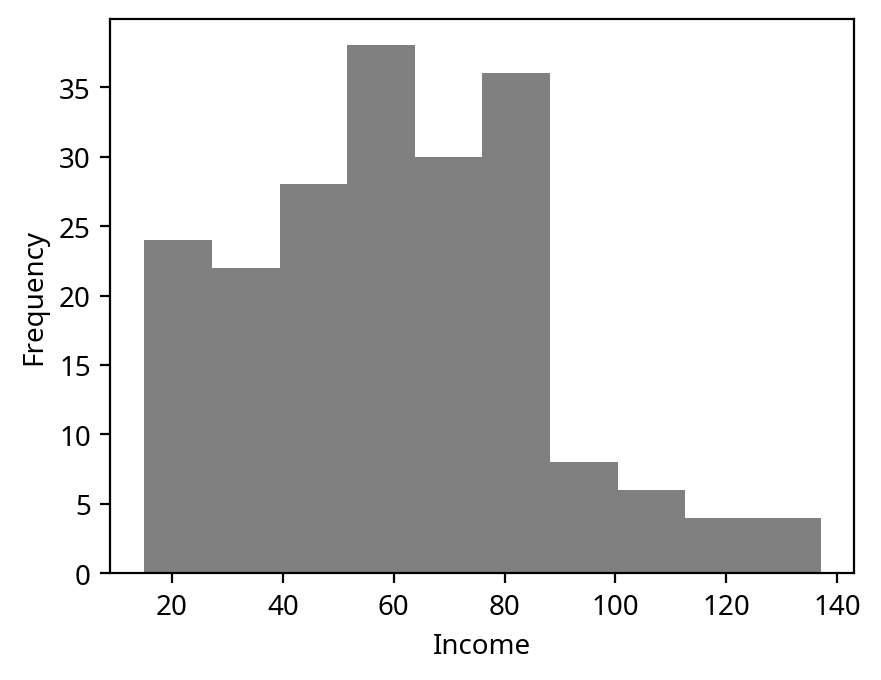

In [17]:
mail_customers.Income.plot.hist(color='gray')
plt.xlabel('Income')
plt.show()

In [18]:
mail_customers['Cluster'] = np.where(mail_customers.Income >= 90, 'High earners', np.where(mail_customers.Income < 50, 'Low income', 'Moderate income' ) )

In [19]:
mail_customers.groupby('Cluster')['Income'].describe()

,count,mean,std,min,25%,50%,75%,max
Cluster,,,,,,,,
High earners,22.0,108.181818,13.661334,93.0,98.25,103.0,118.25,137.0
Low income,72.0,33.027778,11.091136,15.0,22.50,33.5,43.00,49.0
Moderate income,106.0,69.377358,10.651584,50.0,61.00,70.0,78.00,88.0


### Exercise 3.03 Standardizing the Customer Data

## StandardScaler (scikit-learn)

**Module:** `sklearn.preprocessing.StandardScaler`

**Purpose:** Standardizes features by removing the mean and scaling to unit variance, so each feature ends up with **mean = 0** and **standard deviation = 1**.

$$z = \frac{x - \mu}{\sigma}$$

where $\mu$ is the feature's mean and $\sigma$ is its standard deviation, both computed on the training data.

### Basic Usage

```python
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # learn μ, σ from train, then transform
X_test_scaled = scaler.transform(X_test)        # reuse train μ, σ (never refit on test)


In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [21]:
cols_to_scale = ['Age', 'Income', 'Spending_score']

mail_scaled = mail_customers.copy(deep=True)


In [22]:
mail_scaled[cols_to_scale] = scaler.fit_transform(mail_scaled[cols_to_scale])
mail_scaled.describe()

,CustomerID,Age,Income,Spending_score
count,200.000000,2.000000e+02,2.000000e+02,2.000000e+02
mean,100.500000,-1.021405e-16,-2.131628e-16,-1.465494e-16
std,57.879185,1.002509e+00,1.002509e+00,1.002509e+00
min,1.000000,-1.496335e+00,-1.738999e+00,-1.910021e+00
25%,50.750000,-7.248436e-01,-7.275093e-01,-5.997931e-01
50%,100.500000,-2.045351e-01,3.587926e-02,-7.764312e-03
75%,150.250000,7.284319e-01,6.656748e-01,8.851316e-01
max,200.000000,2.235532e+00,2.917671e+00,1.894492e+00


### Exercise 3.04 Calculating Distance Between Clusters

In [23]:
sel_cols = ['Income', 'Spending_score']
cust3 = mail_scaled[sel_cols].head(3)
cust3

,Income,Spending_score
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913


In [24]:
from scipy.spatial.distance import cdist

cdist(cust3, cust3, metric='euclidean')

array([[0.        , 1.63050555, 1.28167999],
       [1.63050555, 0.        , 2.91186723],
       [1.28167999, 2.91186723, 0.        ]])

#### Exercise 3.05 K-Means Clustering on Mall (Mail) Customers

In [25]:
from sklearn.cluster import KMeans

#model =KMeans(n_clusters=N, random_state=random_state)

In [26]:
cluster_cols = ['Income', 'Spending_score']
mail_scaled[cluster_cols].head(3)

,Income,Spending_score
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913


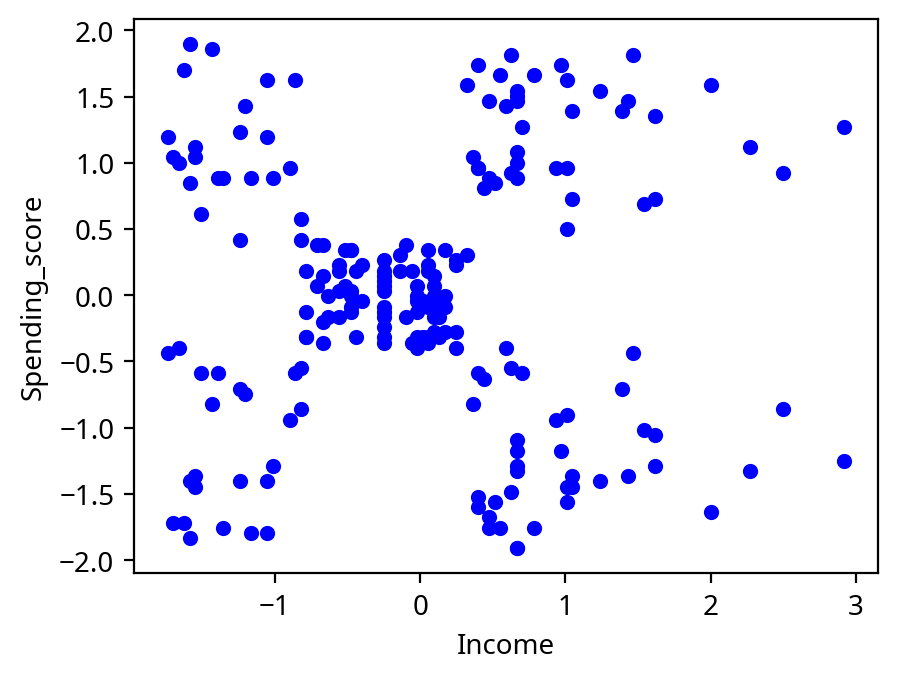

In [27]:
mail_scaled.plot.scatter(x='Income', y='Spending_score', color='blue')
plt.show()

In [28]:
model = KMeans(n_clusters=5, random_state=42)

model.fit(mail_scaled[cluster_cols])

mail_scaled['Cluster'] = model.predict(mail_scaled[cluster_cols])
mail_scaled.head()


/var/mobile/Containers/Data/Application/5933B5E7-F0F8-4CE7-B48A-88579CF74EB0/Documents/site-packages/threadpoolctl.py:990: RuntimeWarning: Could not find dl_iterate_phdr in the C standard library.
  warnings.warn(


,CustomerID,Gender,Age,Income,Spending_score,Cluster
0,1,Male,-1.424569,-1.738999,-0.434801,4
1,2,Male,-1.281035,-1.738999,1.195704,2
2,3,Female,-1.352802,-1.700830,-1.715913,4
3,4,Female,-1.137502,-1.700830,1.040418,2
4,5,Female,-0.563369,-1.662660,-0.395980,4


In [ ]:
markers = ['x', '*', '+', '.', '|', '_']

<ipython-input-29-161060498d74>:5: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(temp.Income, temp.Spending_score, marker=markers[clust], cmap='plasma')
<ipython-input-29-161060498d74>:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


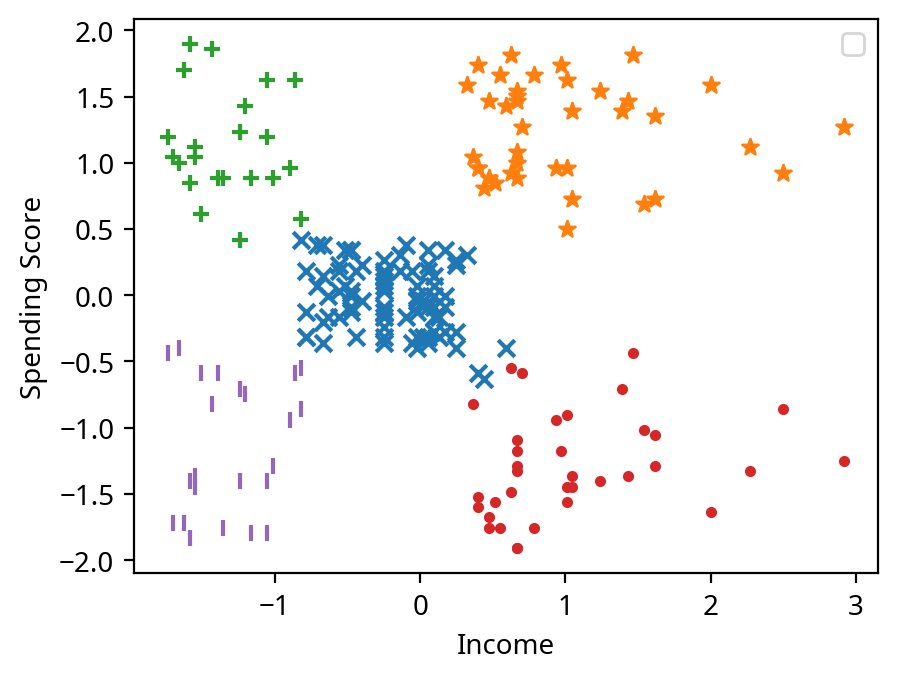

In [29]:
markers = ['x', '*', '+', '.', '|', '_']

for clust in range(5):
    temp = mail_scaled[mail_scaled.Cluster == clust]
    plt.scatter(temp.Income, temp.Spending_score, marker=markers[clust], cmap='plasma')
    
plt.xlabel('Income')
plt.ylabel('Spending Score')
plt.legend()
plt.show()

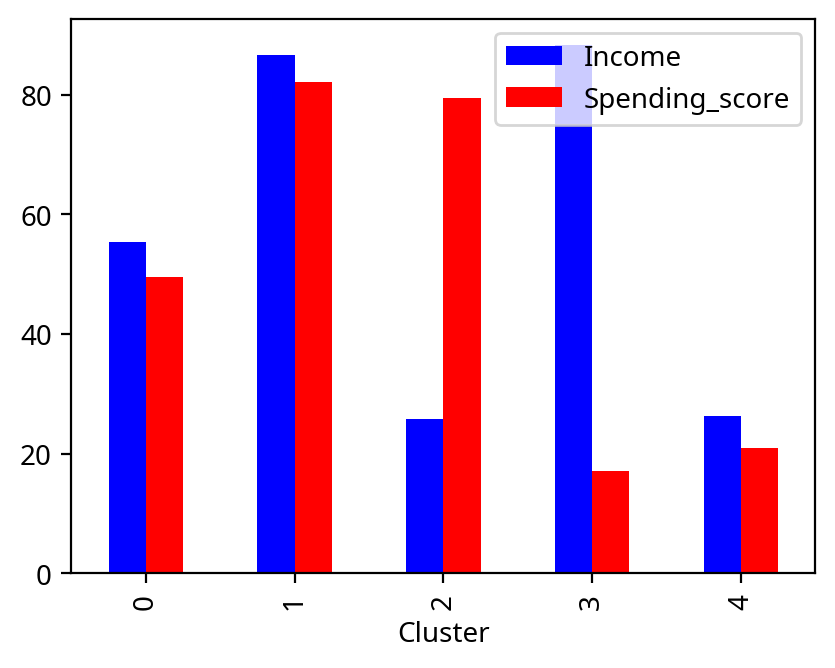

In [30]:
mail_customers['Cluster'] = mail_scaled.Cluster

mail_customers.groupby('Cluster')[['Income', 'Spending_score']].mean().plot.bar(color=['blue', 'red'])
plt.show()

### Activity 3.01 Bank Customer Segmentation

In [31]:
bank1.head()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [32]:
bank1.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


In [33]:
# standard scale the income and ccaverage columns
scale_cols = ['Income', 'CCAvg']

bank1_scaled = bank1.copy(deep=True)

bank1_scaled[scale_cols] = scaler.fit_transform(bank1_scaled[scale_cols])
#mail_scaled[cols_to_scale] = scaler.fit_transform(mail_scaled[cols_to_scale])

bank1_scaled.describe()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,5000.000000,5000.000000,5000.000000,5.000000e+03,5000.000000,5000.000000,5.000000e+03,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,2500.500000,45.338400,20.104600,1.449507e-16,93152.503000,2.396400,-6.394885e-17,1.881000,56.498800,0.096000,0.104400,0.06040,0.596800,0.294000
std,1443.520003,11.463166,11.467954,1.000100e+00,2121.852197,1.147663,1.000100e+00,0.839869,101.713802,0.294621,0.305809,0.23825,0.490589,0.455637
min,1.000000,23.000000,-3.000000,-1.428969e+00,9307.000000,1.000000,-1.108987e+00,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,1250.750000,35.000000,10.000000,-7.554825e-01,91911.000000,1.000000,-7.084116e-01,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,2500.500000,45.000000,20.000000,-2.123482e-01,93437.000000,2.000000,-2.506106e-01,2.000000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000
75%,3750.250000,55.000000,30.000000,5.263146e-01,94608.000000,3.000000,3.216407e-01,3.000000,101.000000,0.000000,0.000000,0.00000,1.000000,1.000000
max,5000.000000,67.000000,43.000000,3.263712e+00,96651.000000,4.000000,4.613525e+00,3.000000,635.000000,1.000000,1.000000,1.00000,1.000000,1.000000


<Axes: xlabel='Income', ylabel='CCAvg'>

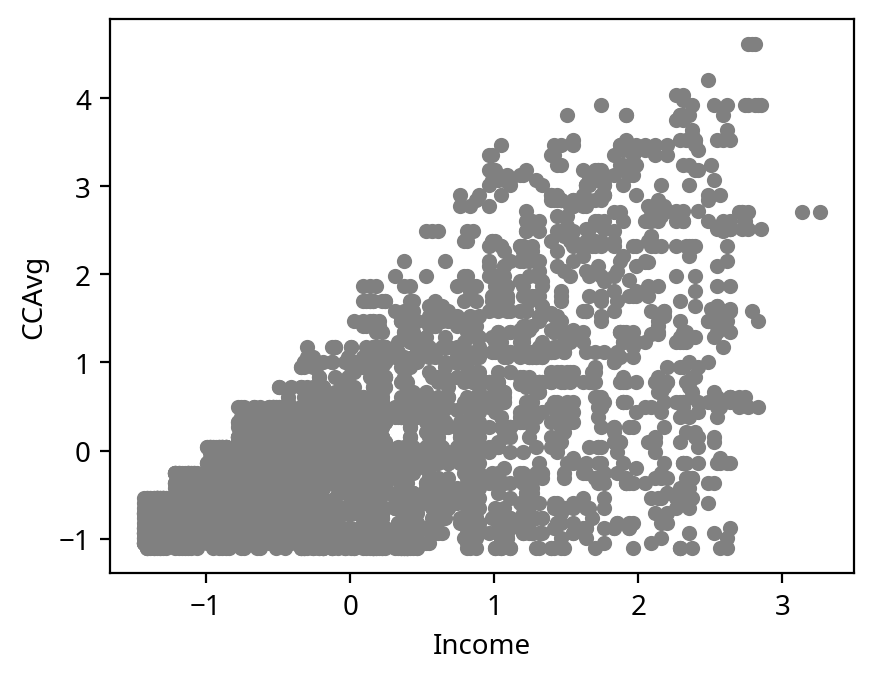

In [34]:
bank1_scaled.plot.scatter(x='Income', y='CCAvg', color='blue')

In [37]:
bank1_scaled[scale_cols].head()


,Income,CCAvg
0,-0.538229,-0.193385
1,-0.864109,-0.250611
2,-1.363793,-0.536736
3,0.569765,0.436091
4,-0.625130,-0.536736


In [38]:
model1 = KMeans(n_clusters=3, random_state=42)

model1.fit(bank1_scaled[scale_cols])

bank1_scaled['Cluster'] = model1.predict(bank1_scaled[scale_cols])
bank1_scaled.head()

#mail_scaled['Cluster'] = model.predict(mail_scaled[cluster_cols])


,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard,Cluster
0,1,25,1,-0.538229,91107,4,-0.193385,1,0,0,1,0,0,0,2
1,2,45,19,-0.864109,90089,3,-0.250611,1,0,0,1,0,0,0,2
2,3,39,15,-1.363793,94720,1,-0.536736,1,0,0,0,0,0,0,2
3,4,35,9,0.569765,94112,1,0.436091,2,0,0,0,0,0,0,0
4,5,35,8,-0.625130,91330,4,-0.536736,2,0,0,0,0,0,1,2


<ipython-input-39-db726b1b1052>:5: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(temp.Income, temp.CCAvg, marker=markers[clust], cmap='plasma')
<ipython-input-39-db726b1b1052>:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


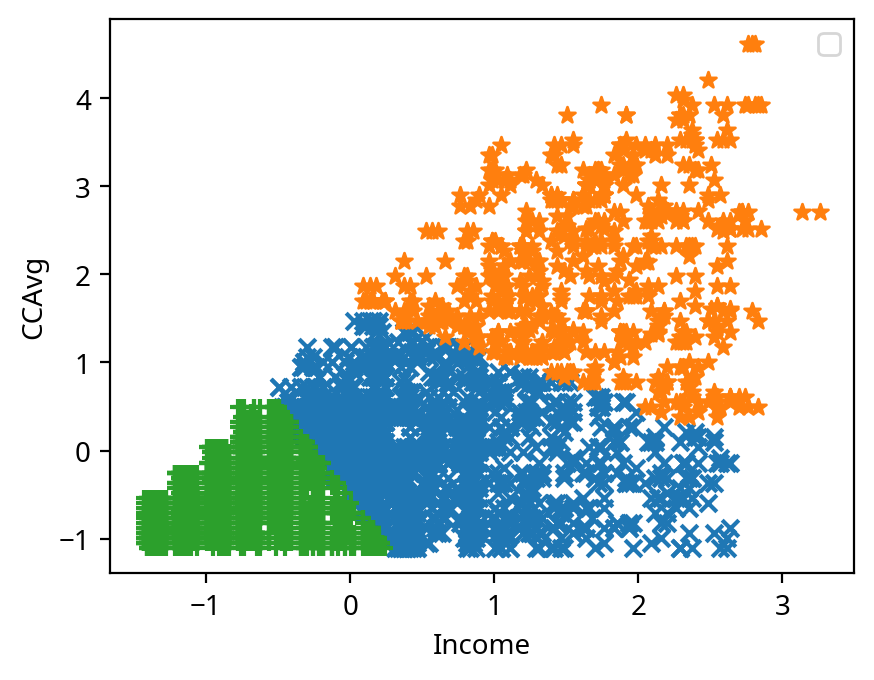

In [39]:

markers = ['x', '*', '+']

for clust in range(3):
    temp = bank1_scaled[bank1_scaled.Cluster == clust]
    plt.scatter(temp.Income, temp.CCAvg, marker=markers[clust], cmap='plasma')
    
plt.xlabel('Income')
plt.ylabel('CCAvg')
plt.legend()
plt.show()

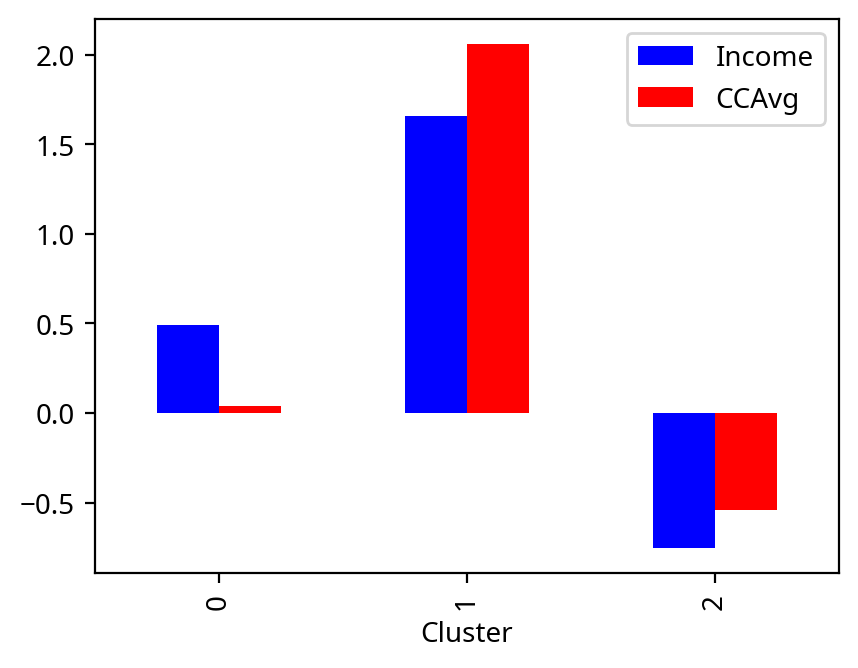

In [41]:
bank1_scaled.groupby('Cluster')[['Income', 'CCAvg']].mean().plot.bar(color=['blue', 'red'])
plt.show()

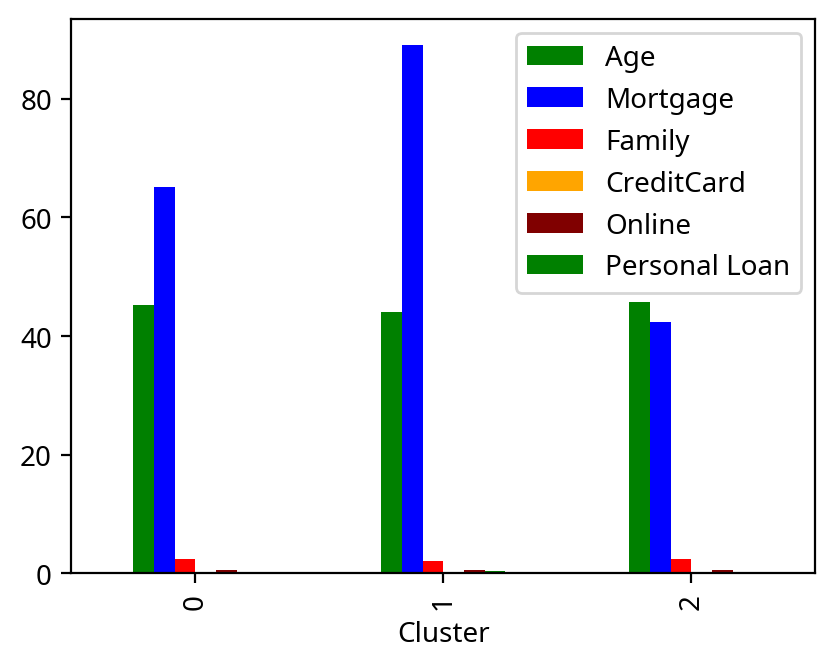

In [47]:
bank1_scaled.groupby('Cluster')[['Age', 'Mortgage','Family','CreditCard', 'Online','Personal Loan']].mean().plot.bar(color=['green', 'blue', 'red', 'orange', 'maroon'])
plt.show()

### Exercise 3.06 High-Dimensional Data

In [48]:
mall_cols2 = ['Age', 'Income', 'Spending_score']
mail_scaled[mall_cols2].head()


,Age,Income,Spending_score
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


In [50]:
model2 = KMeans(n_clusters=4, random_state=42)
model2.fit(mail_scaled[mall_cols2])

mail_scaled['Cluster1'] = model2.predict(mail_scaled[mall_cols2])

In [52]:
from sklearn import decomposition

pca = decomposition.PCA(n_components=2)
pca_res = pca.fit_transform(mail_scaled[mall_cols2])

mail_scaled['pc1'] = pca_res[:,0]
mail_scaled['pc2'] = pca_res[:, 1]

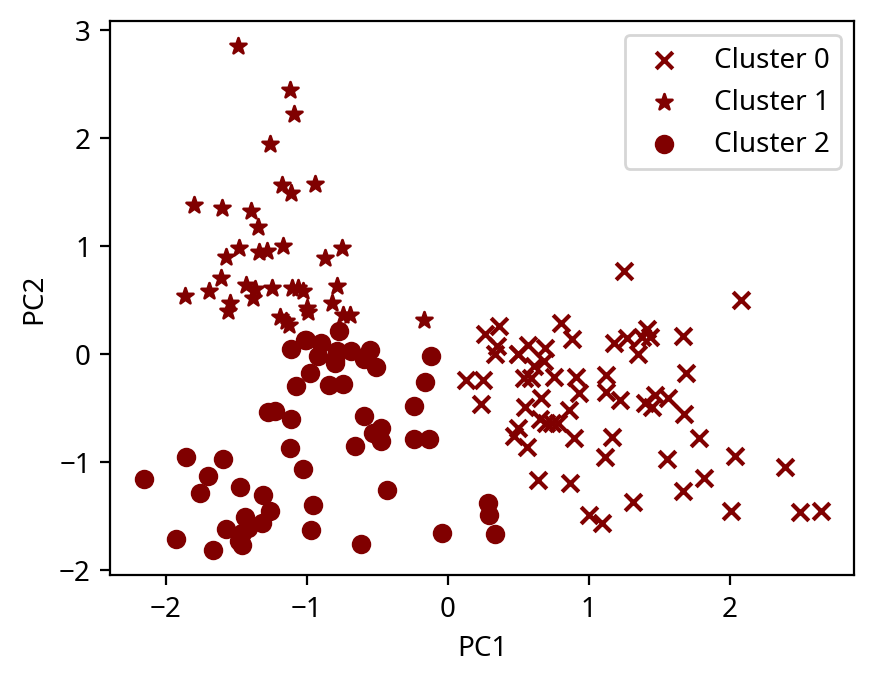

In [57]:
markers1 = ['x', '*', 'o']

for clust in range(3):
    temp = mail_scaled[mail_scaled.Cluster1 == clust]
    plt.scatter(temp.pc1, temp.pc2, marker=markers1[clust], color='maroon', label='Cluster ' + str(clust))
    
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()
